In [ ]:
pip install yfinance pandas numpy matplotlib

Total Strategy Return: 30.10%
Total Buy & Hold Return: 11.99%


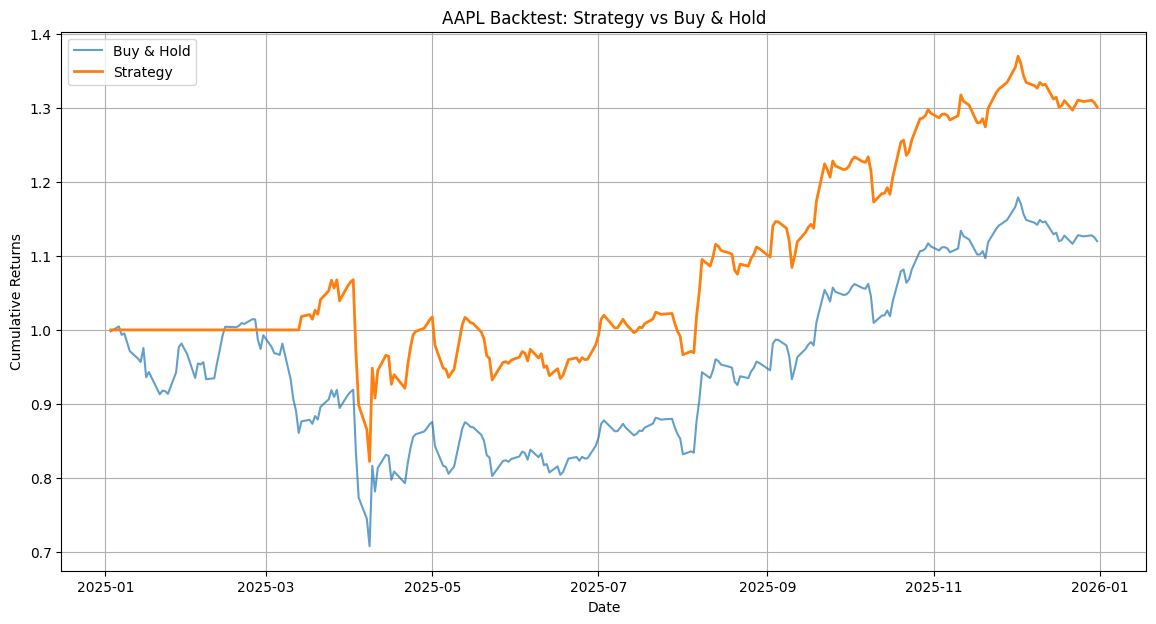

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =============================
# CONFIG
# =============================
SYMBOL = "AAPL"
START_DATE = "2025-01-01"
END_DATE = "2026-01-01"

# =============================
# DOWNLOAD DATA
# =============================
df = yf.download(SYMBOL, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)

# --- FIX CLOSE COLUMN ---
if isinstance(df.columns, pd.MultiIndex):
    close_col = [c for c in df.columns if "Close" in c][-1]
    close = df[close_col]
else:
    close_col = [c for c in df.columns if "Close" in c][0]
    close = df[close_col]

df = pd.DataFrame({"Close": close})

# =============================
# INDICATORS
# =============================
# Moving Average
df["MA"] = df["Close"].rolling(50).mean()

# Bollinger Bands
mid = df["Close"].rolling(20).mean()
std = df["Close"].rolling(20).std()
df["BB_UPPER"] = mid + 2.0 * std
df["BB_LOWER"] = mid - 2.0 * std

# RSI
delta = df["Close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
rs = gain.rolling(16).mean() / loss.rolling(16).mean()
df["RSI"] = 100 - (100 / (1 + rs))

# =============================
# SIGNALS
# =============================
df["Signal"] = 0
df.loc[(df["RSI"] < 20) & (df["Close"] < df["BB_LOWER"]), "Signal"] = 1  # BUY
df.loc[(df["RSI"] > 80) & (df["Close"] > df["BB_UPPER"]), "Signal"] = -1 # SELL

# =============================
# POSITIONS
# =============================
# Forward-fill positions to hold until opposite signal
df["Position"] = df["Signal"].replace(0, np.nan).ffill().fillna(0)

# =============================
# RETURNS
# =============================
df["Market_Returns"] = df["Close"].pct_change()
df["Strategy_Returns"] = df["Position"].shift(1) * df["Market_Returns"]

# Cumulative returns
df["Cumulative_Market"] = (1 + df["Market_Returns"]).cumprod()
df["Cumulative_Strategy"] = (1 + df["Strategy_Returns"]).cumprod()

# =============================
# RESULTS
# =============================
strategy_total = df["Cumulative_Strategy"].iloc[-1] - 1
market_total = df["Cumulative_Market"].iloc[-1] - 1

print(f"Total Strategy Return: {strategy_total:.2%}")
print(f"Total Buy & Hold Return: {market_total:.2%}")

# =============================
# PLOT
# =============================
plt.figure(figsize=(14,7))
plt.plot(df.index, df["Cumulative_Market"], label="Buy & Hold", alpha=0.7)
plt.plot(df.index, df["Cumulative_Strategy"], label="Strategy", linewidth=2)
plt.legend()
plt.title(f"{SYMBOL} Backtest: Strategy vs Buy & Hold")
plt.xlabel("Date")
plt.ylabel("Cumulative Returns")
plt.grid(True)
plt.show()
